# Region-based Image Segmentation

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# reading the image and converting into grayscale using 0
img = cv2.imread('sample.jpg', 0)

# x and y cordinates of starting point
seed = (100, 100)

# maximum allowed intensity variation 
threshold = 15

# getting image dimension
h, w = img.shape

# creating a empty image of same dimesnion as of original image 
segmented = np.zeros((h, w), dtype=np.uint8)


In [ ]:
# now we are using stack to merge similar pixels with that of seed pixel
stack = [seed]

# fetching the pixel value at pixel cordinate of starting point
seed_value = int(img[seed[1], seed[0]])

seed_value

33

In [10]:
while stack:

    # fetching last point of this group  
    x, y = stack.pop()

     
    # checking whether cordinates are outside of image dimension
    if x < 0 or y < 0 or x >= w or y >= h:
        continue

    # checking whether the pixel has already been 
    # included in the segmented region
    if segmented[y, x] == 255:
        continue

    if abs(int(img[y, x]) - seed_value) <= threshold:
        segmented[y, x] = 255

        # Region Growing 
        # We add the four neighboring pixels of the current pixel to the stack.
        stack.extend([
            (x+1, y), (x-1, y),
            (x, y+1), (x, y-1)
        ])



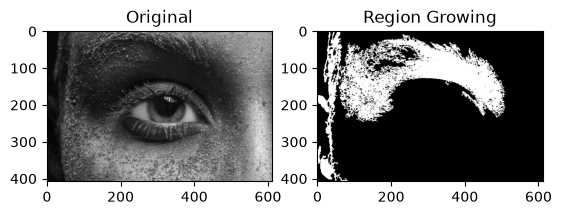

In [11]:
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='gray')
plt.title("Region Growing")

plt.show()